<a href="https://colab.research.google.com/github/bbny27/DSA4212-G1/blob/beckham%2Fexperiment-1/Experiment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install scikit-optimize cma
%pip install git+https://github.com/uber-research/TuRBO.git

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [scikit-optimize]
  Cloning https://github.com/uber-research/TuRBO.git to /tmp/pip-req-build-kwhopmcz
  Running command git clone --filter=blob:none --quiet https://github.com/uber-research/TuRBO.git /tmp/pip-req-build-kwhopmcz
  Resolved https://github.com/uber-research/TuRBO.git to commit de0db39f481d9505bb3610b7b7aa0ebf7702e4a5
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for turbo: filename=turbo-0.0.1-py3-none-any.whl size=12391 sha256=bb4e16b2e61427baa8dca38a3373a34e64e29e42891d6f96e8e31c8445ac9876
  Stored in directory: /tmp/pip-ephem-wheel-cache-z8didhyn/wheels/18/14/72/a54aaaa9cc731e38f10113757498bda9c9b803596744fca710
Successfully built turbo
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [turbo]


In [ ]:
# Numerical calculations, plotting and timing.
import numpy as np
import matplotlib.pyplot as plt
import time

# Bayesian optimisation.
from skopt import gp_minimize
from skopt.space import Real

# Optional custom GP and kernels for BO.
from skopt.learning import GaussianProcessRegressor
from skopt.learning.gaussian_process.kernels import (
    ConstantKernel,
    Matern,
    RBF,
)

# CMA-ES.
import cma

# TuRBO-1 and its random-seed control.
import torch
from turbo import Turbo1

In [ ]:
def two_basin_function(x, c, a, b, r0):
    """Evaluate the two-basin objective at one point x."""
    x = np.asarray(x, dtype=float)
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    # Distance from each basin's centre.
    distance_a = np.linalg.norm(x - a)
    distance_b = np.linalg.norm(x - b)

    # Worse bowl: minimum value 1 at a.
    basin_a = 1.0 + distance_a**2

    # Better bowl: minimum value 0 at b.
    # The penalty is zero within radius r0 of b.
    penalty = c * max(0.0, distance_b - r0)**2
    basin_b = distance_b**2 + penalty

    # Combine the two bowls by taking the lower value.
    return float(min(basin_a, basin_b))

In [ ]:
class BudgetReached(Exception):
    pass


def limit_evaluations(objective, budget):
    """Return a counted objective and its evaluation history."""
    history = {"X": [], "y": []}

    def evaluate(x):
        if len(history["y"]) >= budget:
            raise BudgetReached

        value = float(objective(x))
        history["X"].append(np.asarray(x).copy())
        history["y"].append(value)
        return value

    return evaluate, history

In [ ]:
a = np.array([-2.0, 0.0])
b = np.array([2.0, 0.0])
r0 = 0.5
c = 3.0

bounds = np.array([[-4.0, 4.0], [-4.0, 4.0]])
lower, upper = bounds[:, 0], bounds[:, 1]

budget = 50
seed = 42
n_init = 4

def objective(x):
    return two_basin_function(x, c, a, b, r0)

results = {}

In [ ]:
limited_objective, history = limit_evaluations(objective, budget)
start = time.perf_counter()

try:
    bo_result = gp_minimize(
        func=limited_objective,
        dimensions=[Real(float(lo), float(hi)) for lo, hi in bounds],
        n_calls=budget,
        n_initial_points=n_init,
        acq_func="EI",
        noise=1e-10,
        random_state=seed,
    )
except BudgetReached:
    pass

results["BO"] = {
    "X": np.asarray(history["X"]),
    "y": np.asarray(history["y"]),
    "seconds": time.perf_counter() - start,
}
print("BO finished")

BO finished


In [ ]:
limited_objective, history = limit_evaluations(objective, budget)
rng = np.random.default_rng(seed)

# CMA-ES searches in [0,1]^2; map its points to our original domain.
initial_mean = rng.uniform(size=2)

def cma_objective(u):
    x = lower + (upper - lower) * np.asarray(u)
    return limited_objective(x)

start = time.perf_counter()

try:
    cma_result = cma.fmin2(
        cma_objective,
        initial_mean,
        0.25,
        options={
            "bounds": [0.0, 1.0],
            "maxfevals": budget,
            "seed": seed,
            "verbose": -9,
            "verb_log": 0,
        },
    )
except BudgetReached:
    pass

results["CMA-ES"] = {
    "X": np.asarray(history["X"]),
    "y": np.asarray(history["y"]),
    "seconds": time.perf_counter() - start,
}
print("CMA-ES finished")

CMA-ES finished


In [ ]:
limited_objective, history = limit_evaluations(objective, budget)

np.random.seed(seed)
torch.manual_seed(seed)

start = time.perf_counter()

try:
    turbo_result = Turbo1(
        f=limited_objective,
        lb=lower,
        ub=upper,
        n_init=n_init,
        max_evals=budget,
        batch_size=1,
        use_ard=True,
        n_training_steps=50,
        verbose=False,
        device="cpu",
        dtype="float64",
    )
    turbo_result.optimize()

except BudgetReached:
    pass

results["TuRBO-1"] = {
    "X": np.asarray(history["X"]),
    "y": np.asarray(history["y"]),
    "seconds": time.perf_counter() - start,
}
print("TuRBO-1 finished")

TuRBO-1 finished


BO       | evaluations=50 | best=0.000004 | first f<1: 2 | time=39.8s
CMA-ES   | evaluations=50 | best=0.004302 | first f<1: 21 | time=0.0s
TuRBO-1  | evaluations=50 | best=1.000533 | first f<1: None | time=15.6s


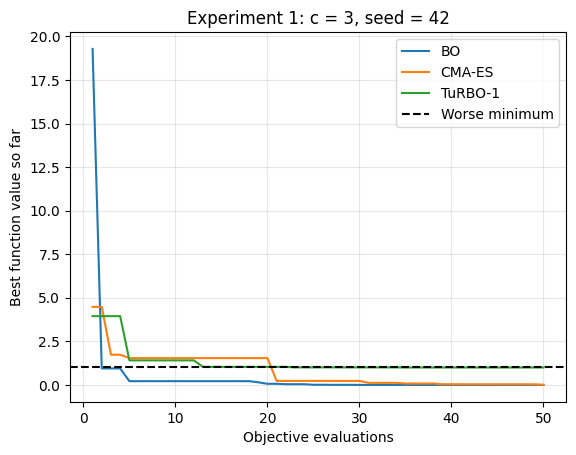

In [ ]:
for name, result in results.items():
    y = result["y"]
    hits = np.flatnonzero(y < 1.0)
    first_hit = int(hits[0] + 1) if len(hits) else None

    print(
        f"{name:8s} | evaluations={len(y):2d} "
        f"| best={y.min():.6f} "
        f"| first f<1: {first_hit} "
        f"| time={result['seconds']:.1f}s"
    )

    plt.plot(
        np.arange(1, len(y) + 1),
        np.minimum.accumulate(y),
        label=name,
    )

plt.axhline(1.0, color="black", linestyle="--", label="Worse minimum")
plt.xlabel("Objective evaluations")
plt.ylabel("Best function value so far")
plt.title("Experiment 1: c = 3, seed = 42")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
# REPEATED EXPERIMENT: c = 3, five seeds, 50 evaluations per method.
# First run cells 0-4 (installation, imports, objective, counter, settings).
# The original seed-42 results above are kept separately in results.
repeat_seeds = [0, 1, 2, 3, 4]
repeat_c = 3.0
repeat_budget = 50
repeat_n_init = 4
methods = ["BO", "CMA-ES", "TuRBO-1"]
repeated_results = {name: {} for name in methods}

def repeat_objective(x):
    return two_basin_function(x, repeat_c, a, b, r0)

for run_seed in repeat_seeds:
    for name in methods:
        limited_objective, history = limit_evaluations(
            repeat_objective, repeat_budget
        )
        start = time.perf_counter()
        try:
            if name == "BO":
                gp_minimize(
                    func=limited_objective,
                    dimensions=[Real(float(lo), float(hi)) for lo, hi in bounds],
                    n_calls=repeat_budget,
                    n_initial_points=repeat_n_init,
                    acq_func="EI", noise=1e-10,
                    random_state=run_seed,
                )
            elif name == "CMA-ES":
                # Use normalised coordinates, as in the single-run cell.
                rng = np.random.default_rng(run_seed)
                initial_mean = rng.uniform(size=len(bounds))
                cma.fmin2(
                    lambda u: limited_objective(
                        lower + (upper - lower) * np.asarray(u)
                    ),
                    initial_mean, 0.25,
                    options={
                        "bounds": [0.0, 1.0],
                        "maxfevals": repeat_budget,
                        # cma treats seed=0 specially; use a positive seed.
                        "seed": run_seed + 1,
                        "verbose": -9, "verb_log": 0,
                    },
                )
            else:
                np.random.seed(run_seed)
                torch.manual_seed(run_seed)
                optimiser = Turbo1(
                    f=limited_objective, lb=lower, ub=upper,
                    n_init=repeat_n_init, max_evals=repeat_budget,
                    batch_size=1, use_ard=True, n_training_steps=50,
                    verbose=False, device="cpu", dtype="float64",
                )
                optimiser.optimize()
        except BudgetReached:
            pass  # Stop before exceeding the common evaluation budget.

        y = np.asarray(history["y"], dtype=float)
        hits = np.flatnonzero(y < 1.0)
        repeated_results[name][run_seed] = {
            "X": np.asarray(history["X"]),
            "y": y,
            "best_so_far": np.minimum.accumulate(y),
            "first_hit": int(hits[0] + 1) if len(hits) else None,
            "seconds": time.perf_counter() - start,
        }
        print(
            f"seed={run_seed} | {name:8s} | evaluations={len(y)} "
            f"| best={y.min():.6f} | success={bool(len(hits))}",
            flush=True,
        )

print("All 15 runs completed. Run the next cell for the summary.")


seed=0 | BO       | evaluations=50 | best=0.000000 | success=True
seed=0 | CMA-ES   | evaluations=50 | best=0.040781 | success=True
seed=0 | TuRBO-1  | evaluations=50 | best=1.000130 | success=False
seed=1 | BO       | evaluations=50 | best=1.000006 | success=False
seed=1 | CMA-ES   | evaluations=50 | best=0.127893 | success=True
seed=1 | TuRBO-1  | evaluations=50 | best=1.001250 | success=False
seed=2 | BO       | evaluations=50 | best=0.000278 | success=True
seed=2 | CMA-ES   | evaluations=50 | best=0.275257 | success=True
seed=2 | TuRBO-1  | evaluations=50 | best=0.000261 | success=True
seed=3 | BO       | evaluations=50 | best=1.001026 | success=False
seed=3 | CMA-ES   | evaluations=50 | best=1.081935 | success=False
seed=3 | TuRBO-1  | evaluations=50 | best=0.000244 | success=True
seed=4 | BO       | evaluations=50 | best=0.000004 | success=True
seed=4 | CMA-ES   | evaluations=50 | best=0.002797 | success=True
seed=4 | TuRBO-1  | evaluations=50 | best=0.000140 | success=True
All 1

,method,seed,evaluations,final_best,first_f_below_1,seconds
0,BO,0,50,1.156564e-07,6.0,50.081357
1,BO,1,50,1.000006e+00,NaN,28.326214
2,BO,2,50,2.775427e-04,7.0,24.267484
3,BO,3,50,1.001026e+00,NaN,28.506123
4,BO,4,50,3.581669e-06,12.0,21.698381
5,CMA-ES,0,50,4.078115e-02,36.0,0.019541
6,CMA-ES,1,50,1.278928e-01,39.0,0.021250
7,CMA-ES,2,50,2.752569e-01,1.0,0.020668
8,CMA-ES,3,50,1.081935e+00,NaN,0.025030
9,CMA-ES,4,50,2.796883e-03,14.0,0.015647


,method,successes,success_rate,median_final_best,median_seconds
0,BO,3/5,0.6,0.000278,28.326214
1,CMA-ES,4/5,0.8,0.127893,0.020668
2,TuRBO-1,3/5,0.6,0.000261,9.233918


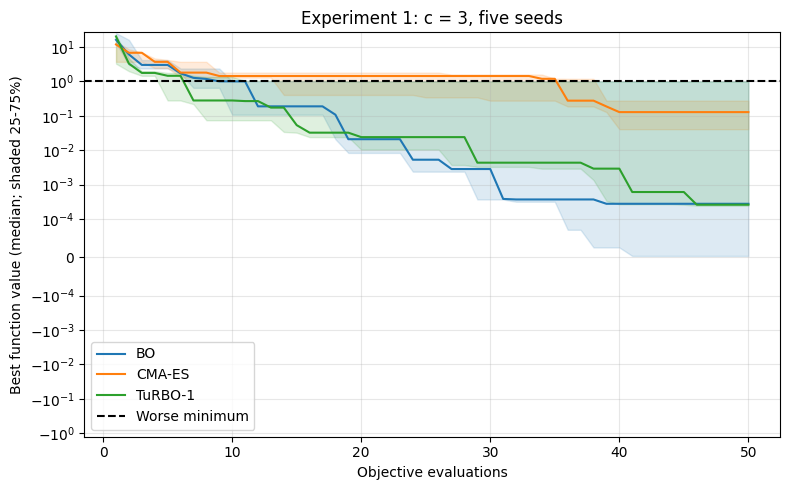

In [11]:
# SUMMARY: all five final values, success rates and median progress.
import pandas as pd
from IPython.display import display

if not all(len(repeated_results[name]) == len(repeat_seeds) for name in methods):
    raise RuntimeError("Run the repeated-experiment cell to completion first.")

rows = []
summary_rows = []
fig, ax = plt.subplots(figsize=(8, 5))

for name in methods:
    runs = [repeated_results[name][s] for s in repeat_seeds]
    final_values = [r["best_so_far"][-1] for r in runs]
    successes = sum(r["first_hit"] is not None for r in runs)
    for s, r in zip(repeat_seeds, runs):
        rows.append({
            "method": name, "seed": s, "evaluations": len(r["y"]),
            "final_best": r["best_so_far"][-1],
            "first_f_below_1": r["first_hit"],
            "seconds": r["seconds"],
        })
    summary_rows.append({
        "method": name,
        "successes": f"{successes}/{len(runs)}",
        "success_rate": successes / len(runs),
        "median_final_best": np.median(final_values),
        "median_seconds": np.median([r["seconds"] for r in runs]),
    })

    # If an optimiser stops early, carry its last best value forward.
    curves = np.stack([
        np.pad(r["best_so_far"],
               (0, repeat_budget - len(r["y"])), mode="edge")
        for r in runs
    ])
    median = np.median(curves, axis=0)
    q25, q75 = np.quantile(curves, [0.25, 0.75], axis=0)
    line, = ax.plot(np.arange(1, repeat_budget + 1), median, label=name)
    ax.fill_between(np.arange(1, repeat_budget + 1), q25, q75,
                    color=line.get_color(), alpha=0.15)

run_table = pd.DataFrame(rows)
summary_table = pd.DataFrame(summary_rows)
display(run_table)
display(summary_table)

ax.axhline(1.0, color="black", linestyle="--", label="Worse minimum")
ax.set_yscale("symlog", linthresh=1e-4)
ax.set_xlabel("Objective evaluations")
ax.set_ylabel("Best function value (median; shaded 25-75%)")
ax.set_title(f"Experiment 1: c = {repeat_c:g}, five seeds")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
import json
from pathlib import Path

# Fixed conditions: only c and the random seed change.
c_values = [0.0, 3.0, 10.0, 30.0]
seeds = list(range(20))
methods = ["BO", "CMA-ES", "TuRBO-1", "Random"]

a = np.array([-2.0, 0.0])
b = np.array([2.0, 0.0])
r0 = 0.5
bounds = np.array([[-4.0, 4.0], [-4.0, 4.0]])
lower, upper = bounds[:, 0], bounds[:, 1]

budget = 50
n_init = 4

# Checkpoint configuration prevents accidentally mixing different setups.
config = {
    "c_values": c_values,
    "seeds": seeds,
    "methods": methods,
    "a": a.tolist(),
    "b": b.tolist(),
    "r0": r0,
    "bounds": bounds.tolist(),
    "budget": budget,
    "n_init": n_init,
    "bo_acquisition": "EI",
    "bo_noise": 1e-10,
    "cma_sigma0": 0.25,
    "turbo_training_steps": 50,
}

checkpoint = Path("experiment1_sweep.json")

if checkpoint.exists():
    saved = json.loads(checkpoint.read_text())
    if saved["config"] != config:
        raise ValueError(
            "Checkpoint settings differ. Rename the checkpoint "
            "before starting a different experiment."
        )
    sweep_runs = saved["runs"]
else:
    sweep_runs = []

completed = {
    (r["c"], r["seed"], r["method"])
    for r in sweep_runs
}
print(f"Resuming with {len(completed)}/320 trials completed.", flush=True)

for c_value in c_values:
    for run_seed in seeds:
        for name in methods:
            key = (c_value, run_seed, name)
            if key in completed:
                continue

            # Fix the objective for this difficulty.
            def objective(x):
                return two_basin_function(x, c_value, a, b, r0)

            # Fresh evaluation counter for every trial.
            evaluate, history = limit_evaluations(objective, budget)
            start = time.perf_counter()

            try:
                if name == "BO":
                    gp_minimize(
                        func=evaluate,
                        dimensions=[
                            Real(float(lo), float(hi))
                            for lo, hi in bounds
                        ],
                        n_calls=budget,
                        n_initial_points=n_init,
                        initial_point_generator="random",
                        acq_func="EI",
                        noise=1e-10,
                        random_state=run_seed,
                    )

                elif name == "CMA-ES":
                    rng = np.random.default_rng(run_seed)
                    initial_mean = rng.uniform(size=len(bounds))

                    # Search in [0,1]^2 and map back to the true domain.
                    cma.fmin2(
                        lambda u: evaluate(
                            lower + (upper - lower) * np.asarray(u)
                        ),
                        initial_mean,
                        0.25,
                        options={
                            "bounds": [0.0, 1.0],
                            "maxfevals": budget,
                            # Avoid cma's special treatment of seed=0.
                            "seed": run_seed + 1,
                            "verbose": -9,
                            "verb_log": 0,
                        },
                    )

                elif name == "TuRBO-1":
                    np.random.seed(run_seed)
                    torch.manual_seed(run_seed)

                    optimiser = Turbo1(
                        f=evaluate,
                        lb=lower,
                        ub=upper,
                        n_init=n_init,
                        max_evals=budget,
                        batch_size=1,
                        use_ard=True,
                        n_training_steps=50,
                        verbose=False,
                        device="cpu",
                        dtype="float64",
                    )
                    optimiser.optimize()

                else:
                    # Independent uniform random-search baseline.
                    rng = np.random.default_rng(run_seed)
                    points = rng.uniform(
                        lower, upper,
                        size=(budget, len(bounds)),
                    )
                    for x in points:
                        evaluate(x)

            except BudgetReached:
                pass

            elapsed = time.perf_counter() - start
            y = np.asarray(history["y"], dtype=float)
            hits = np.flatnonzero(y < 1.0)

            record = {
                "c": c_value,
                "seed": run_seed,
                "method": name,
                "evaluations": len(y),
                "success": bool(len(hits)),
                "first_hit": int(hits[0] + 1) if len(hits) else None,
                "final_best": float(y.min()),
                "seconds": elapsed,
                "X": np.asarray(history["X"]).tolist(),
                "y": y.tolist(),
            }
            sweep_runs.append(record)
            completed.add(key)

            # Save after every completed trial.
            temporary = checkpoint.with_suffix(".tmp")
            temporary.write_text(json.dumps({
                "config": config,
                "runs": sweep_runs,
            }))
            temporary.replace(checkpoint)

            print(
                f"[{len(completed):3d}/320] c={c_value:g} "
                f"| seed={run_seed:2d} | {name:8s} "
                f"| n={len(y)} | best={y.min():.6f} "
                f"| success={bool(len(hits))} | {elapsed:.1f}s",
                flush=True,
            )

print("Experiment complete.")

Resuming with 0/320 trials completed.
[  1/320] c=0 | seed= 0 | BO       | n=50 | best=0.000514 | success=True | 37.9s
[  2/320] c=0 | seed= 0 | CMA-ES   | n=50 | best=0.000030 | success=True | 0.0s
[  3/320] c=0 | seed= 0 | TuRBO-1  | n=50 | best=1.000228 | success=False | 9.3s
[  4/320] c=0 | seed= 0 | Random   | n=50 | best=0.004248 | success=True | 0.0s
[  5/320] c=0 | seed= 1 | BO       | n=50 | best=1.001933 | success=False | 27.4s
[  6/320] c=0 | seed= 1 | CMA-ES   | n=50 | best=0.017293 | success=True | 0.0s
[  7/320] c=0 | seed= 1 | TuRBO-1  | n=50 | best=0.000324 | success=True | 9.3s
[  8/320] c=0 | seed= 1 | Random   | n=50 | best=0.093904 | success=True | 0.0s
[  9/320] c=0 | seed= 2 | BO       | n=50 | best=0.000011 | success=True | 25.9s
[ 10/320] c=0 | seed= 2 | CMA-ES   | n=50 | best=0.368703 | success=True | 0.0s
[ 11/320] c=0 | seed= 2 | TuRBO-1  | n=50 | best=0.000358 | success=True | 9.5s
[ 12/320] c=0 | seed= 2 | Random   | n=50 | best=0.269257 | success=True | 0.

,c,method,runs,successes,success_rate,median_final_best,median_seconds,min_evaluations,max_evaluations
0,0.0,BO,20,18,0.90,0.000056,26.118957,50,50
1,0.0,CMA-ES,20,18,0.90,0.046890,0.017532,50,50
2,0.0,TuRBO-1,20,18,0.90,0.000291,9.066109,50,50
3,0.0,Random,20,19,0.95,0.168714,0.001696,50,50
4,3.0,BO,20,11,0.55,0.084733,26.239049,50,50
5,3.0,CMA-ES,20,16,0.80,0.129770,0.018402,50,50
6,3.0,TuRBO-1,20,12,0.60,0.001081,8.962640,50,50
7,3.0,Random,20,16,0.80,0.168714,0.001734,50,50
8,10.0,BO,20,7,0.35,1.000170,25.637886,50,50
9,10.0,CMA-ES,20,12,0.60,0.728572,0.019979,50,50


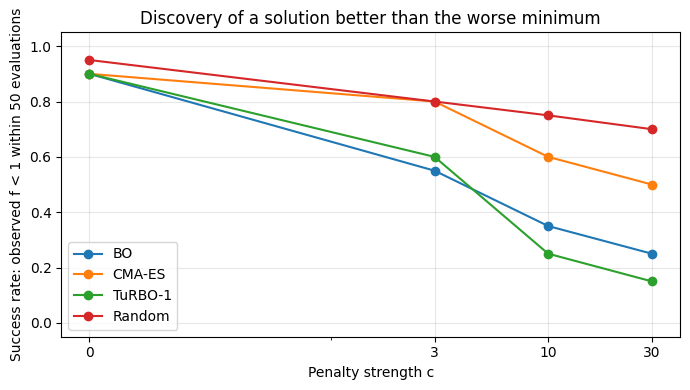

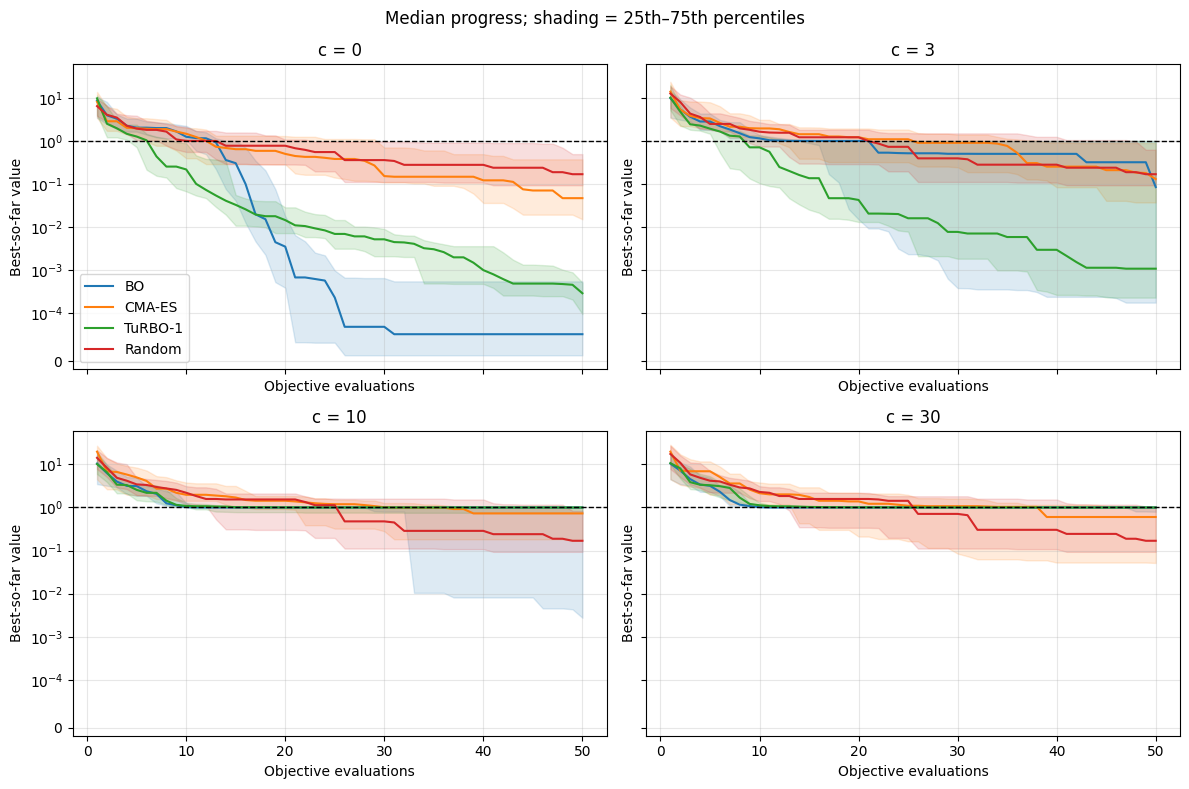

In [13]:
import pandas as pd
from IPython.display import display

# Reload saved results, so this also works after reconnecting.
saved = json.loads(Path("experiment1_sweep.json").read_text())
sweep_runs = saved["runs"]
cfg = saved["config"]
methods = cfg["methods"]
c_values = cfg["c_values"]
budget = cfg["budget"]

# Individual trial results.
trial_table = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("X", "y")}
    for r in sweep_runs
])

# Summary for each difficulty and method.
summary = (
    trial_table.groupby(["c", "method"], sort=False)
    .agg(
        runs=("success", "size"),
        successes=("success", "sum"),
        success_rate=("success", "mean"),
        median_final_best=("final_best", "median"),
        median_seconds=("seconds", "median"),
        min_evaluations=("evaluations", "min"),
        max_evaluations=("evaluations", "max"),
    )
    .reset_index()
)

display(summary)
trial_table.to_csv("experiment1_trials.csv", index=False)
summary.to_csv("experiment1_summary.csv", index=False)

# Keep method colours consistent across all plots.
colours = dict(zip(methods, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))

# Plot 1: probability of beating the worse minimum within the budget.
fig, ax = plt.subplots(figsize=(7, 4))

for name in methods:
    part = summary[summary["method"] == name].sort_values("c")
    ax.plot(
        part["c"], part["success_rate"],
        marker="o", label=name, color=colours[name],
    )

ax.set_xscale("symlog", linthresh=1)
ax.set_xticks(c_values)
ax.set_xticklabels([f"{c:g}" for c in c_values])
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("Penalty strength c")
ax.set_ylabel(f"Success rate: observed f < 1 within {budget} evaluations")
ax.set_title("Discovery of a solution better than the worse minimum")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Plot 2: progress curves for each difficulty.
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
evaluation_counts = np.arange(1, budget + 1)

for ax, c_value in zip(axes.flat, c_values):
    for name in methods:
        runs = [
            r for r in sweep_runs
            if r["c"] == c_value and r["method"] == name
        ]
        if not runs:
            continue

        # Retain the last best value if a method stopped early.
        curves = []
        for r in runs:
            curve = np.minimum.accumulate(r["y"])
            curves.append(np.pad(
                curve, (0, budget - len(curve)), mode="edge"
            ))
        curves = np.stack(curves)

        median = np.median(curves, axis=0)
        q25, q75 = np.quantile(curves, [0.25, 0.75], axis=0)

        ax.plot(
            evaluation_counts, median,
            label=name, color=colours[name],
        )
        ax.fill_between(
            evaluation_counts, q25, q75,
            color=colours[name], alpha=0.15,
        )

    ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
    ax.set_yscale("symlog", linthresh=1e-4)
    ax.set_title(f"c = {c_value:g}")
    ax.set_xlabel("Objective evaluations")
    ax.set_ylabel("Best-so-far value")
    ax.grid(alpha=0.3)

axes[0, 0].legend()
fig.suptitle("Median progress; shading = 25th–75th percentiles")
plt.tight_layout()
plt.show()

Concentration summary: proportions range from 0 to 1


,c,method,success,runs,mean_last20_near_a,mean_last20_in_better_bowl,fraction_ever_in_better_bowl
0,0.0,BO,True,18,0.019,0.942,1.000
1,0.0,CMA-ES,True,18,0.019,0.900,1.000
2,0.0,TuRBO-1,False,2,0.750,0.175,1.000
3,0.0,Random,True,19,0.050,0.558,1.000
4,0.0,BO,False,2,0.900,0.075,1.000
5,0.0,TuRBO-1,True,18,0.008,0.936,1.000
6,0.0,CMA-ES,False,2,0.650,0.075,1.000
7,0.0,Random,False,1,0.050,0.400,1.000
8,3.0,BO,True,11,0.064,0.886,1.000
9,3.0,CMA-ES,True,16,0.056,0.647,1.000


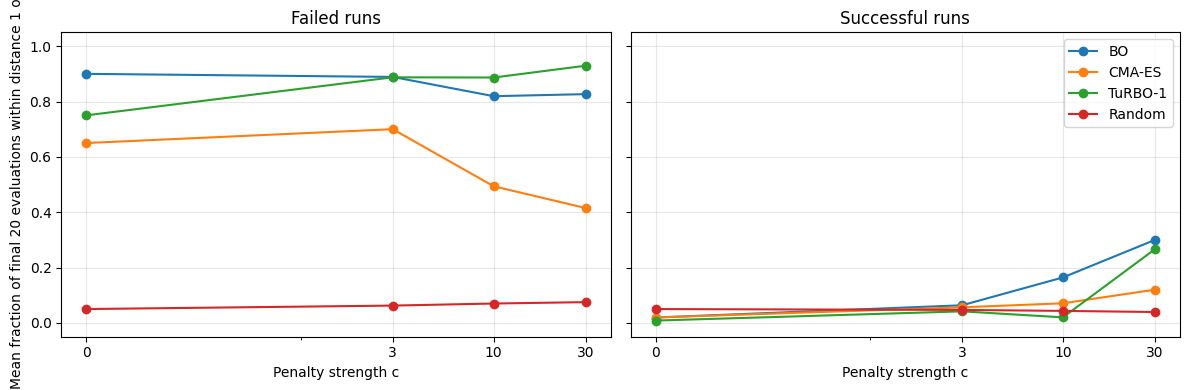

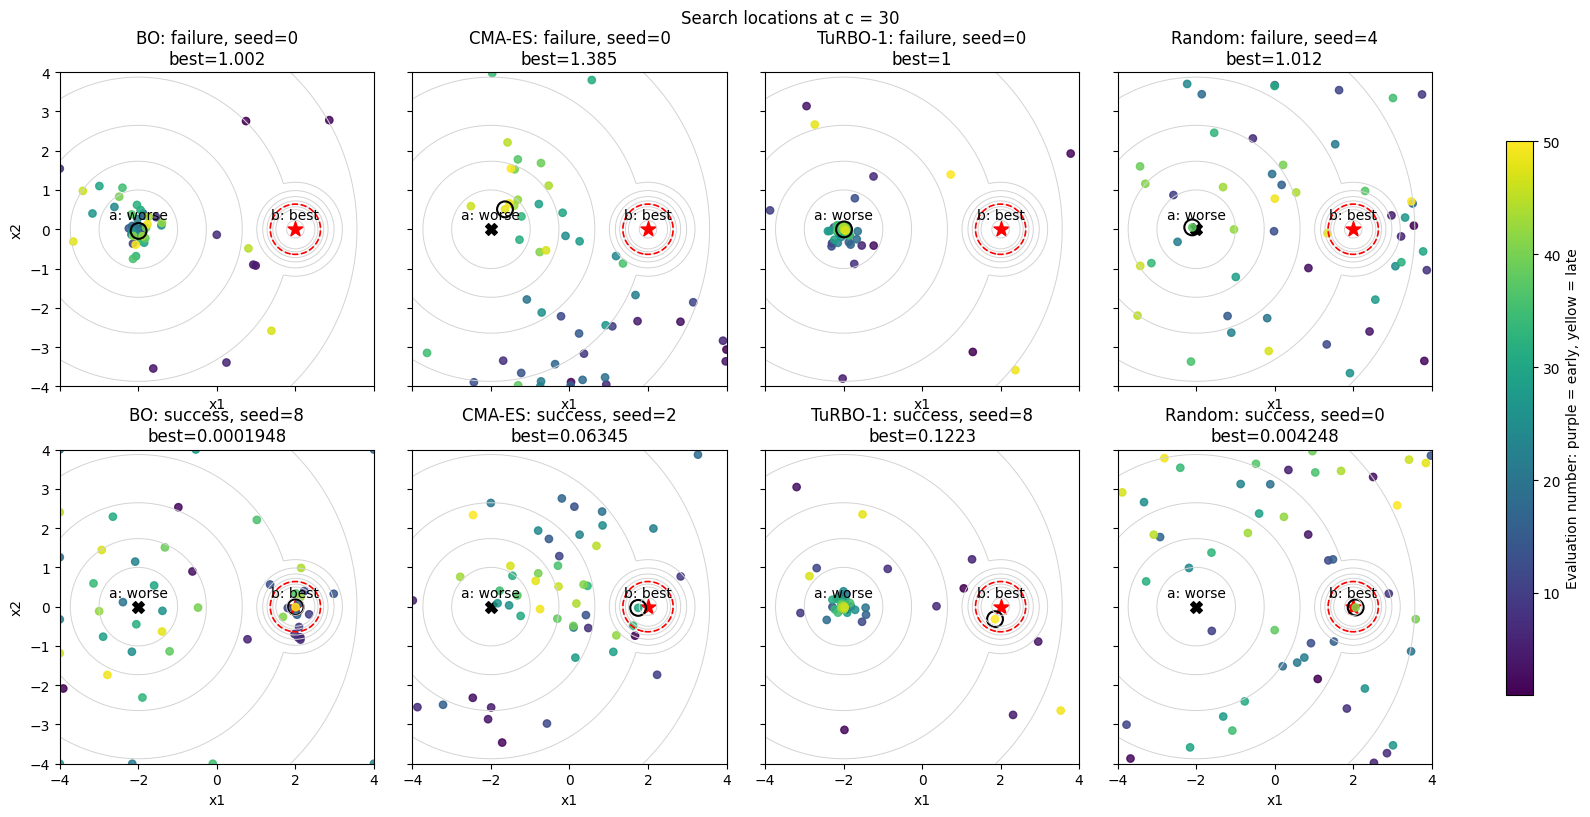

,method,status,seed,best
0,BO,failure,0,1.001861
1,BO,success,8,0.000195
2,CMA-ES,failure,0,1.385053
3,CMA-ES,success,2,0.063446
4,TuRBO-1,failure,0,1.000182
5,TuRBO-1,success,8,0.122332
6,Random,failure,4,1.012215
7,Random,success,0,0.004248


In [15]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Load the existing experiment data.
saved = json.loads(Path("experiment1_sweep.json").read_text())
runs = saved["runs"]
cfg = saved["config"]

a = np.asarray(cfg["a"], dtype=float)
b = np.asarray(cfg["b"], dtype=float)
r0 = cfg["r0"]
bounds = np.asarray(cfg["bounds"], dtype=float)
methods = cfg["methods"]

# Diagnostic definition: "near a" means distance <= 1.
# This fixed radius is a descriptive choice, not a basin boundary.
near_a_radius = 1.0
last_n = 20

# ----------------------------------------------------------
# 1. Measure concentration using ALL recorded runs.
# ----------------------------------------------------------
rows = []

for run in runs:
    X = np.asarray(run["X"], dtype=float)
    y = np.asarray(run["y"], dtype=float)

    distance_a = np.linalg.norm(X - a, axis=1)
    distance_b = np.linalg.norm(X - b, axis=1)

    # The better bowl is active wherever it is lower than the worse bowl.
    qa = 1.0 + distance_a**2
    qb = (
        distance_b**2
        + run["c"] * np.maximum(0.0, distance_b - r0)**2
    )
    better_bowl_active = qb < qa

    hits = np.flatnonzero(y < 1.0)

    rows.append({
        "c": run["c"],
        "method": run["method"],
        "seed": run["seed"],
        "success": bool(len(hits)),
        "final_best": float(y.min()),
        "last20_near_a": np.mean(distance_a[-last_n:] <= near_a_radius),
        "last20_in_better_bowl": np.mean(better_bowl_active[-last_n:]),
        "ever_in_better_bowl": bool(better_bowl_active.any()),
        "first_hit": int(hits[0] + 1) if len(hits) else np.nan,
    })

diagnostics = pd.DataFrame(rows)

concentration_summary = (
    diagnostics.groupby(["c", "method", "success"], sort=False)
    .agg(
        runs=("seed", "size"),
        mean_last20_near_a=("last20_near_a", "mean"),
        mean_last20_in_better_bowl=("last20_in_better_bowl", "mean"),
        fraction_ever_in_better_bowl=("ever_in_better_bowl", "mean"),
    )
    .reset_index()
)

print("Concentration summary: proportions range from 0 to 1")
display(concentration_summary.round(3))

# Plot concentration separately for successful and failed runs.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, success in zip(axes, [False, True]):
    subset = diagnostics[diagnostics["success"] == success]

    for name in methods:
        part = (
            subset[subset["method"] == name]
            .groupby("c")["last20_near_a"]
            .mean()
        )
        ax.plot(part.index, part.values, marker="o", label=name)

    ax.set_xscale("symlog", linthresh=1)
    ax.set_xticks(cfg["c_values"])
    ax.set_xticklabels([f"{c:g}" for c in cfg["c_values"]])
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("Penalty strength c")
    ax.set_title("Successful runs" if success else "Failed runs")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean fraction of final 20 evaluations within distance 1 of a")
axes[1].legend()
plt.tight_layout()
plt.show()

# ----------------------------------------------------------
# 2. Example search trajectories at c = 30.
#    Choose the lowest seed in each success/failure group.
# ----------------------------------------------------------
c_to_plot = 30.0

x1 = np.linspace(bounds[0, 0], bounds[0, 1], 250)
x2 = np.linspace(bounds[1, 0], bounds[1, 1], 250)
G1, G2 = np.meshgrid(x1, x2)

DA = np.sqrt((G1 - a[0])**2 + (G2 - a[1])**2)
DB = np.sqrt((G1 - b[0])**2 + (G2 - b[1])**2)

QA = 1.0 + DA**2
QB = DB**2 + c_to_plot * np.maximum(0.0, DB - r0)**2
F = np.minimum(QA, QB)

fig, axes = plt.subplots(
    2, len(methods),
    figsize=(4 * len(methods), 8),
    sharex=True, sharey=True,
    constrained_layout=True,
)

selected_rows = []

for col, name in enumerate(methods):
    for row, success in enumerate([False, True]):
        ax = axes[row, col]

        ax.contour(
            G1, G2, F,
            levels=[0.05, 0.25, 0.5, 1, 2, 4, 8, 16, 32],
            colors="lightgray",
            linewidths=0.7,
        )

        # Red dashed boundary encloses the success region f < 1.
        ax.contour(
            G1, G2, F, levels=[1.0],
            colors="red", linestyles="--", linewidths=1.2,
        )

        ax.scatter(*a, marker="X", color="black", s=70)
        ax.scatter(*b, marker="*", color="red", s=130)
        ax.text(a[0], a[1] + 0.25, "a: worse", ha="center")
        ax.text(b[0], b[1] + 0.25, "b: best", ha="center")

        candidates = sorted(
            [
                r for r in runs
                if r["c"] == c_to_plot
                and r["method"] == name
                and bool(r["success"]) == success
            ],
            key=lambda r: r["seed"],
        )

        status = "success" if success else "failure"

        if not candidates:
            ax.set_title(f"{name}: no {status} runs")
        else:
            run = candidates[0]
            X = np.asarray(run["X"])
            y = np.asarray(run["y"])

            # Colour shows evaluation order; points are not connected
            # because successive evaluations need not form a path.
            ax.scatter(
                X[:, 0], X[:, 1],
                c=np.arange(1, len(X) + 1),
                cmap="viridis", vmin=1, vmax=cfg["budget"],
                s=28, alpha=0.85,
            )

            # Circle the best evaluated point.
            best = X[np.argmin(y)]
            ax.scatter(
                *best, s=130,
                facecolors="none", edgecolors="black",
                linewidths=1.5,
            )

            ax.set_title(
                f"{name}: {status}, seed={run['seed']}\n"
                f"best={y.min():.4g}"
            )

            selected_rows.append({
                "method": name,
                "status": status,
                "seed": run["seed"],
                "best": float(y.min()),
            })

        ax.set_aspect("equal")
        ax.set_xlim(bounds[0])
        ax.set_ylim(bounds[1])
        ax.set_xlabel("x1")
        if col == 0:
            ax.set_ylabel("x2")

colour_scale = plt.cm.ScalarMappable(
    norm=plt.Normalize(1, cfg["budget"]),
    cmap="viridis",
)
fig.colorbar(
    colour_scale, ax=axes.ravel().tolist(),
    label="Evaluation number: purple = early, yellow = late",
    shrink=0.8,
)
fig.suptitle(f"Search locations at c = {c_to_plot:g}")
plt.show()

display(pd.DataFrame(selected_rows))

In [16]:
import base64
import hashlib
import requests
from pathlib import Path
from google.colab import userdata

# Source file in Colab.
local_file = Path("experiment1_sweep.json")

# Destination on your personal branch.
repo = "bbny27/DSA4212-G1"
branch = "beckham/experiment-1"
github_path = "results/experiment1_sweep.json"

# Read the file before accessing the token.
content = local_file.read_bytes()

with requests.Session() as session:
    session.headers.update({
        "Authorization": f"Bearer {userdata.get('GITHUB_TOKEN')}",
        "Accept": "application/vnd.github+json",
        "X-GitHub-Api-Version": "2026-03-10",
    })

    url = f"https://api.github.com/repos/{repo}/contents/{github_path}"

    # Get the existing file's SHA, required when replacing it.
    response = session.get(url, params={"ref": branch}, timeout=30)

    if response.status_code not in (200, 404):
        response.raise_for_status()

    existing_sha = (
        response.json()["sha"] if response.status_code == 200 else None
    )

    # Avoid creating another commit when the content hasn't changed.
    local_sha = hashlib.sha1(
        f"blob {len(content)}\0".encode() + content
    ).hexdigest()

    if existing_sha == local_sha:
        print("Already up to date.")
    else:
        payload = {
            "message": "Update Experiment 1 numerical results",
            "branch": branch,
            "content": base64.b64encode(content).decode(),
        }
        if existing_sha:
            payload["sha"] = existing_sha

        uploaded = session.put(url, json=payload, timeout=60)
        uploaded.raise_for_status()
        print("Saved:", uploaded.json()["content"]["html_url"])

Already up to date.
